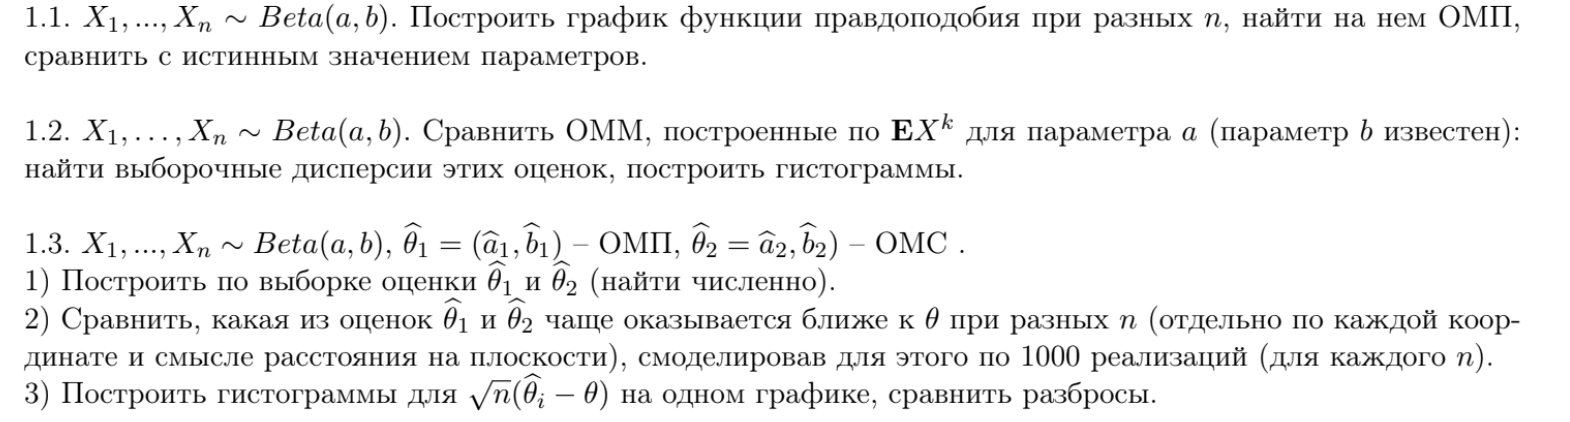

In [6]:
import random
import numpy as np
import math
from scipy.stats import norm, beta
import pandas as pd
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from scipy.optimize import minimize
import matplotlib.pyplot as plt

# **1**

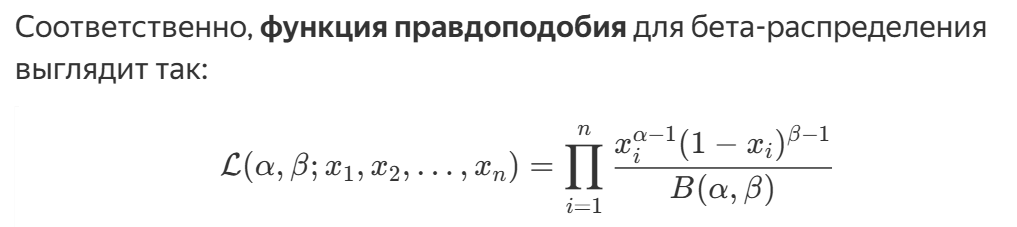

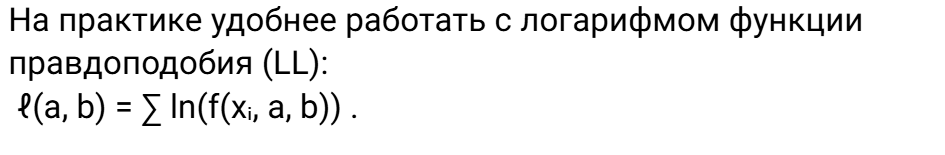

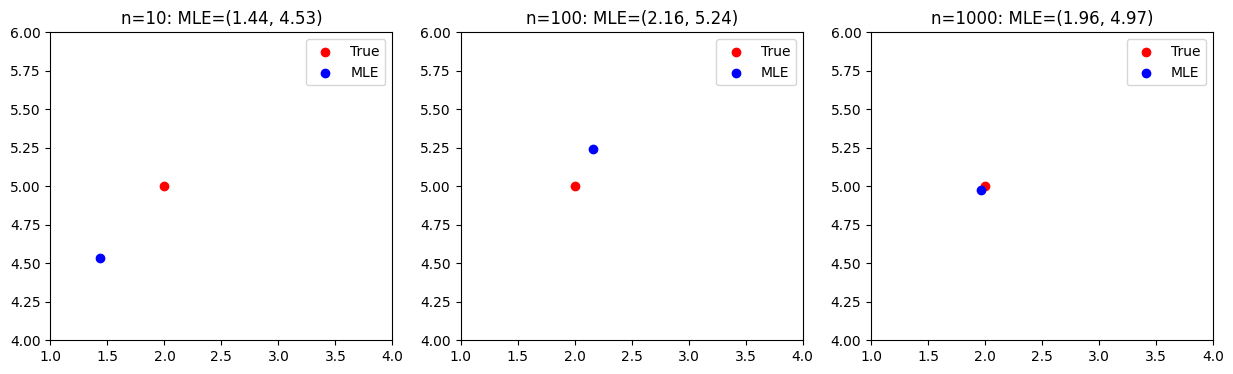

In [16]:
a_true, b_true = 2.0, 5.0

# вычисляет логарифм функции правдоподобия
def log_likelihood(params, data):
    a, b = params
    if a <= 0 or b <= 0: return 1e10
    return -np.sum(beta.logpdf(data, a, b))

n_values = [10, 100, 1000]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, n in enumerate(n_values):
    data = beta.rvs(a_true, b_true, size=n)

    # Поиск ОМП
    res = minimize(log_likelihood, [1, 1], args=(data,), bounds=((0.01, None), (0.01, None)))
    a_mle, b_mle = res.x


    # Визуализация (для упрощения: контурный график не всегда нагляден,
    # лучше отобразить точку ОМП на фоне истинного значения)
    axes[i].set_title(f"n={n}: MLE=({a_mle:.2f}, {b_mle:.2f})")
    axes[i].scatter(a_true, b_true, color='red', label='True',)
    axes[i].scatter(a_mle, b_mle, color='blue', label='MLE')
    axes[i].legend()
    axes[i].set_xlim(1,4)
    axes[i].set_ylim(4,6)

plt.show()

Оценка ОМП: a_hat = 2.3010, b_hat = 5.4269


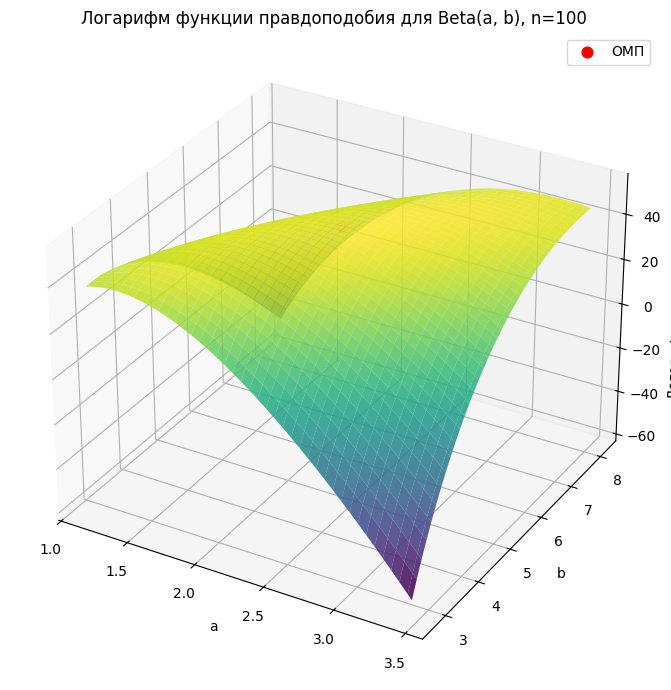

In [9]:
# Истинные параметры распределения
a_true = 2.0
b_true = 5.0
n = 100

# Генерируем выборку
data = beta.rvs(a_true, b_true, size=n)

# Отрицательное логарифмическое правдоподобие:
# минимизируем его, что эквивалентно максимизации правдоподобия.
def negative_log_likelihood(params):
    a, b = params
    if a <= 0 or b <= 0:
        return np.inf
    return -np.sum(beta.logpdf(data, a, b))

# Находим ОМП
result = minimize(
    negative_log_likelihood,
    x0=[1.0, 1.0],
    method="L-BFGS-B",
    bounds=[(1e-6, None), (1e-6, None)]
)

a_hat, b_hat = result.x
print(f"Оценка ОМП: a_hat = {a_hat:.4f}, b_hat = {b_hat:.4f}")

# Сетка параметров для построения поверхности
a_values = np.linspace(max(0.2, a_hat * 0.5), a_hat * 1.5, 80)
b_values = np.linspace(max(0.2, b_hat * 0.5), b_hat * 1.5, 80)
A, B = np.meshgrid(a_values, b_values)

# Считаем логарифм правдоподобия в точках сетки
LL = np.empty_like(A)
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        LL[i, j] = np.sum(beta.logpdf(data, A[i, j], B[i, j]))

# Поверхность лог-правдоподобия
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(A, B, LL, cmap="viridis", alpha=0.85)
ax.scatter(
    a_hat, b_hat,
    np.sum(beta.logpdf(data, a_hat, b_hat)),
    color="red", s=60, label="ОМП"
)

ax.set_xlabel("a")
ax.set_ylabel("b")
ax.set_zlabel("Логарифм правдоподобия")
ax.set_title("Логарифм функции правдоподобия для Beta(a, b), n=100")
ax.legend()

plt.tight_layout()
plt.show()


# **2**

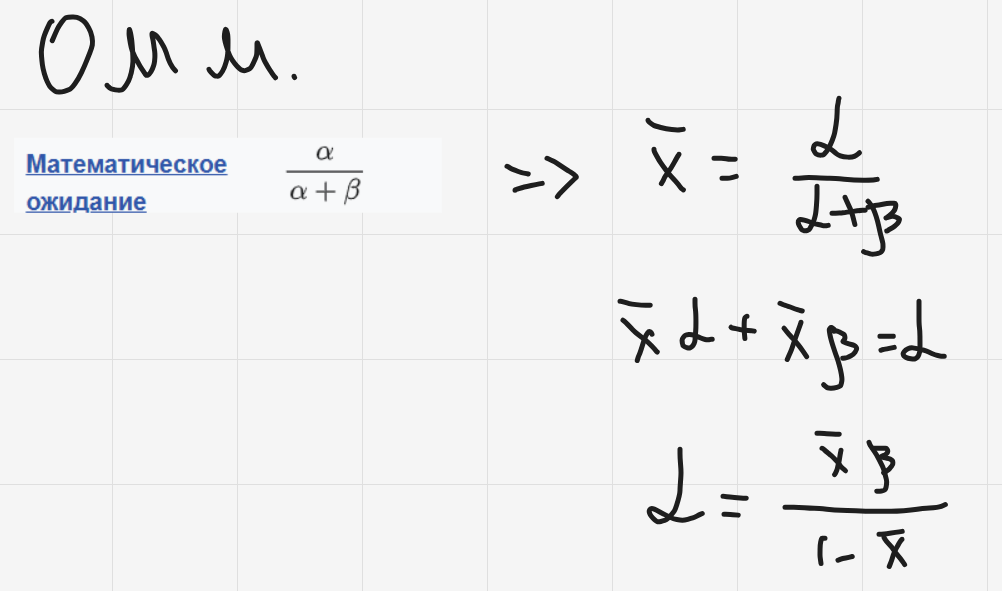

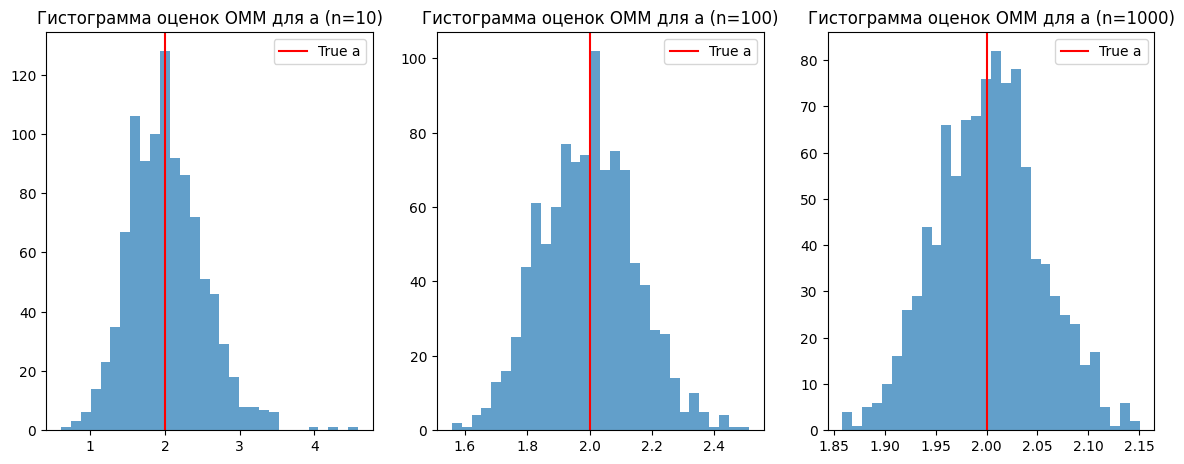

In [39]:
def omm(data, b_known):
    x_bar = np.mean(data)
    return (b_known * x_bar) / (1 - x_bar)

# Моделирование

n_values = [10, 100, 1000]

fig = plt.figure(figsize=(12, 5))
i=1
for n in n_values:
  samples = [omm(beta.rvs(a_true, b_true, size=n), b_true) for _ in range(1000)]
  plt.subplot(1, 3, i)
  plt.hist(samples, bins=30, alpha=0.7)
  i=i+1
  plt.axvline(a_true, color='red', label='True a')
  plt.title(f"Гистограмма оценок OMM для a (n={n})")
  plt.legend()

plt.tight_layout(pad=2.0)
plt.show()



# **3**

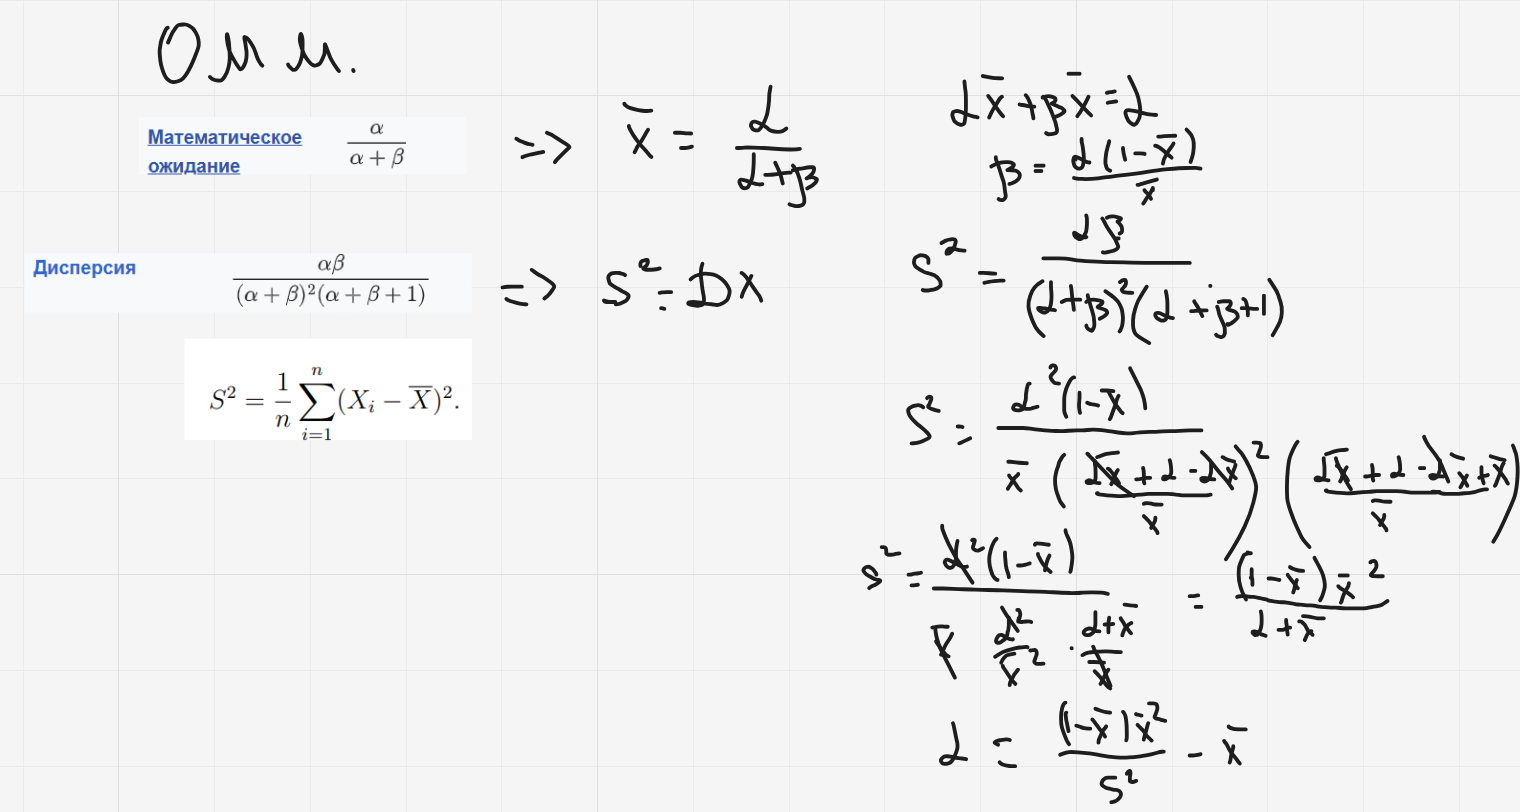

n=50: MLE чаще ближе в 53.6% случаев


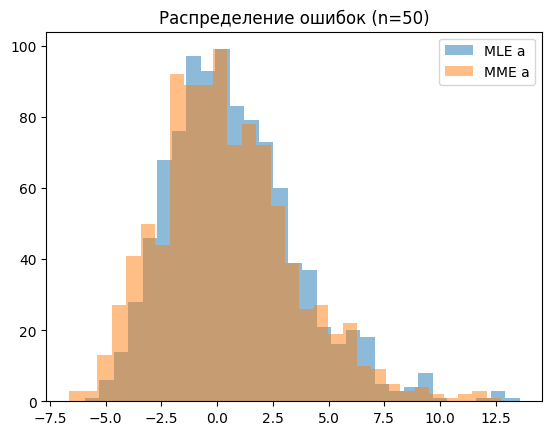

n=200: MLE чаще ближе в 54.5% случаев


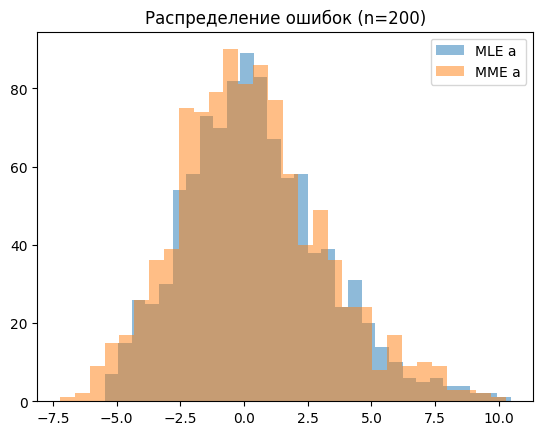

In [44]:
def get_mme(data):
    #омм по формуле выше
    mean = np.mean(data)
    var = np.var(data, ddof=1)

    a=(1-mean)* mean*mean/var-mean
    b=a*(1-mean)/mean
    return np.array([a, b])

def get_mle(data):
    #омп
    def neg_log_lik(params):
        return -np.sum(beta.logpdf(data, params[0], params[1]))

    # Начальное приближение берем из метода моментов
    res = minimize(neg_log_lik, get_mme(data), bounds=((0.01, None), (0.01, None)))
    return res.x

a_true, b_true = 2.0, 5.0
n_values = [50, 200]
n_simulations = 1000

for n in n_values:
    estimates_mle = []
    estimates_mme = []

    for _ in range(n_simulations):
        sample = np.random.beta(a_true, b_true, n)
        estimates_mle.append(get_mle(sample))
        estimates_mme.append(get_mme(sample))

    estimates_mle = np.array(estimates_mle)
    estimates_mme = np.array(estimates_mme)

    # 2) Сравнение близости к истине
    err_mle = np.linalg.norm(estimates_mle - [a_true, b_true], axis=1)
    err_mme = np.linalg.norm(estimates_mme - [a_true, b_true], axis=1)
    print(f"n={n}: MLE чаще ближе в {np.mean(err_mle < err_mme)*100:.1f}% случаев")

    # 3) Гистограммы для sqrt(n)*(theta_hat - theta)
    plt.figure()
    diff_mle = np.sqrt(n) * (estimates_mle - [a_true, b_true])
    diff_mme = np.sqrt(n) * (estimates_mme - [a_true, b_true])

    plt.hist(diff_mle[:, 0], bins=30, alpha=0.5, label='MLE a')
    plt.hist(diff_mme[:, 0], bins=30, alpha=0.5, label='MME a')
    plt.title(f"Распределение ошибок (n={n})")
    plt.legend()
    plt.show()
